# Phases 5–7 (run 2) — Fine-tuning mBERT, MuRIL and IndicBERT + evaluation (Colab)

**Before you start:** `Runtime → Change runtime type → T4 GPU`.

Upload `hinglish-sentiment-analysis.zip` to the top level of your Google Drive (`MyDrive/`).

**Run 2 changes:** training goes up to **10 epochs** (early-stopping patience 3) because in run 1
MuRIL was still improving at epoch 5. IndicBERT now works after a Hugging Face login (it is a gated model).

**For IndicBERT, before running:**
1. Log in at huggingface.co, open https://huggingface.co/ai4bharat/indic-bert and accept/submit the access form.
2. Create a *Read* token at https://huggingface.co/settings/tokens.
3. Paste it when the login cell asks. If access isn't granted, the notebook skips IndicBERT and continues.

Run the cells top to bottom. Total time on a free T4 is about **50–65 min**:

| Step | What | Runs | ~Time |
|---|---|---|---|
| A | Learning-rate sweep (seed 42) | 3 models × 2 LRs | 25–30 min |
| B | Extra seeds at each model's best LR | 3 models × 2 seeds | 25–30 min |
| C | *(off by default)* raw vs cleaned text ablation (already done in run 1) | 3 runs | ~14 min |

Results are copied to `MyDrive/hinglish_outputs_run2/` after every step, so a Colab disconnect doesn't lose finished runs.
Model selection (best epoch, best LR, best checkpoint) uses **validation macro-F1 only**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ZIP = '/content/drive/MyDrive/snlp_project/hinglish-sentiment-analysis.zip'   
DRIVE_OUT   = '/content/drive/MyDrive/snlp_project/hinglish_outputs_run2'

!rm -rf /content/hinglish-sentiment-analysis
!unzip -q -o "$PROJECT_ZIP" -d /content/
%cd /content/hinglish-sentiment-analysis
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
/content/hinglish-sentiment-analysis
app.py	data  notebooks  outputs  README.md  requirements.txt  src


In [ ]:
!pip install -q sentencepiece emoji wordfreq
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, transformers
print('torch', torch.__version__, '| transformers', transformers.__version__, '| CUDA:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'No GPU - set Runtime > Change runtime type > T4 GPU'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 18.7 MB/s eta 0:00:00
name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.11.0+cu130 | transformers 5.18.0 | CUDA: True


In [ ]:
import os, subprocess
def sync():
    """Copy results (not the large model checkpoints) to Drive."""
    os.makedirs(DRIVE_OUT, exist_ok=True)
    subprocess.run(f'rsync -a --exclude models/ outputs/ {DRIVE_OUT}/', shell=True, check=True)
    print('synced ->', DRIVE_OUT)

## Hugging Face login (needed for IndicBERT)

In [ ]:
from huggingface_hub import login
login()   

In [ ]:
# Check IndicBERT access; skip it (and keep going) if the gated repo isn't open to you yet
from transformers import AutoConfig
MODELS = ['mbert', 'muril', 'indicbert']
try:
    AutoConfig.from_pretrained('ai4bharat/indic-bert')
    print('IndicBERT access OK')
except Exception as e:
    print('IndicBERT NOT accessible -> skipping it:', str(e).splitlines()[0])
    MODELS.remove('indicbert')
print('Models to train:', MODELS)

config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

IndicBERT access OK
Models to train: ['mbert', 'muril', 'indicbert']


## Step A — Learning-rate sweep (seed 42)
Each run trains for up to 10 epochs with early stopping (patience 3) on validation macro-F1.
LRs {3e-5, 5e-5}: in run 1, 2e-5 was never the best on validation.

In [ ]:
for m in MODELS:
    !python src/transformer_models.py --model {m} --seeds 42 --lrs 3e-5 5e-5
    sync()

device: cuda (Tesla T4)

RUN mbert_lr3e-05_seed42_text_clean   (bert-base-multilingual-cased)
config.json: 100% 625/625 [00:00<00:00, 1.98MB/s]
tokenizer_config.json: 100% 49.0/49.0 [00:00<00:00, 165kB/s]
vocab.txt: 100% 996k/996k [00:00<00:00, 4.32MB/s]
tokenizer.json: 100% 1.96M/1.96M [00:00<00:00, 6.20MB/s]

model.safetensors: downloading bytes:  33% 237M/714M [00:02<00:02, 177MB/s, 20.4MB/s  ]
model.safetensors: downloading bytes:  38% 271M/714M [00:02<00:02, 167MB/s, 22.8MB/s  ]
model.safetensors: downloading bytes:  44% 314M/714M [00:02<00:03, 130MB/s, 26.4MB/s  ]
model.safetensors: downloading bytes:  76% 540M/714M [00:04<00:01, 168MB/s, 41.6MB/s  ]
model.safetensors: downloading bytes:  93% 668M/714M [00:05<00:00, 165MB/s, 49.9MB/s  ]
model.safetensors: reconstructing file:  94% 670M/714M [00:06<00:00, 139MB/s, 27.0MB/s  ] 
model.safetensors: downloading bytes: 100% 676M/676M [00:06<00:00, 107MB/s, 51.3MB/s  ]
model.safetensors: reconstructing file: 100% 714M/714M [00:06<00:00,

In [ ]:
import pandas as pd
runs = pd.read_csv('outputs/results/transformer_runs.csv')
sweep = runs[(runs.seed == 42) & (runs.text_col == 'text_clean')]
print(sweep[['model','lr','best_epoch','validation_macro_f1','test_macro_f1']]
      .sort_values(['model','lr']).to_string(index=False))

# Best LR per model, chosen on VALIDATION macro-F1
BEST_LR = sweep.loc[sweep.groupby('alias').validation_macro_f1.idxmax()].set_index('alias').lr.to_dict()
print('\nBest LR per model (by val):', BEST_LR)

    model      lr  best_epoch  validation_macro_f1  test_macro_f1
IndicBERT 0.00003          10             0.514295       0.467564
IndicBERT 0.00005           7             0.654433       0.585203
    MuRIL 0.00003           6             0.731541       0.656701
    MuRIL 0.00005           8             0.680669       0.629105
    mBERT 0.00003           8             0.671235       0.591574
    mBERT 0.00005           5             0.699366       0.649801

Best LR per model (by val): {'indicbert': 5e-05, 'mbert': 5e-05, 'muril': 3e-05}


## Step B — Two more seeds at each model's best LR
Seed 42 at the best LR already exists from Step A, so this gives 3 seeds per model → mean ± std.

In [ ]:
for m, lr in BEST_LR.items():
    !python src/transformer_models.py --model {m} --seeds 43 44 --lrs {lr}
    sync()

device: cuda (Tesla T4)

RUN indicbert_lr5e-05_seed43_text_clean   (ai4bharat/indic-bert)
Loading weights: 100% 25/25 [00:00<00:00, 13538.75it/s]
[transformers] AlbertForSequenceClassification LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     | 
---------------------------------+------------+-
predictions.LayerNorm.bias       | UNEXPECTED | 
predictions.bias                 | UNEXPECTED | 
predictions.decoder.weight       | UNEXPECTED | 
sop_classifier.classifier.weight | UNEXPECTED | 
sop_classifier.classifier.bias   | UNEXPECTED | 
predictions.decoder.bias         | UNEXPECTED | 
predictions.LayerNorm.weight     | UNEXPECTED | 
predictions.dense.bias           | UNEXPECTED | 
predictions.dense.weight         | UNEXPECTED | 
classifier.weight                | MISSING    | 
classifier.bias                  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:

In [ ]:
runs = pd.read_csv('outputs/results/transformer_runs.csv')
final = runs[runs.apply(lambda r: r.text_col == 'text_clean' and r.lr == BEST_LR.get(r.alias), axis=1)]
summary = (final.groupby('model')[['validation_macro_f1','test_macro_f1','test_accuracy','test_f1_negative']]
                .agg(['mean','std']).round(4))
print(summary.to_string())
base = pd.read_csv('outputs/results/baseline_results.csv')
b = base.loc[base.validation_macro_f1.idxmax()]
print(f'\nBest classical (chosen on val): {b.model}  test macro-F1 {b.test_macro_f1:.4f}')

          validation_macro_f1         test_macro_f1         test_accuracy         test_f1_negative        
                         mean     std          mean     std          mean     std             mean     std
model                                                                                                     
IndicBERT              0.4879  0.1503        0.4373  0.1339        0.5006  0.0988           0.3189  0.2767
MuRIL                  0.7039  0.0240        0.6286  0.0254        0.6518  0.0270           0.5638  0.0362
mBERT                  0.6942  0.0072        0.6402  0.0231        0.6793  0.0224           0.5461  0.0402

Best classical (chosen on val): Char Linear SVM  test macro-F1 0.6732


## Step C — *(optional)* Ablation: cleaned vs raw text on the best model
Already done in run 1 (no meaningful difference), so it's off by default. Set `RUN_ABLATION = True` to repeat it.

In [ ]:
RUN_ABLATION = False
best_alias = final.groupby('alias').validation_macro_f1.mean().idxmax()
print('Best model by mean val macro-F1:', best_alias, '@ lr', BEST_LR[best_alias])
if RUN_ABLATION:
    !python src/transformer_models.py --model {best_alias} --seeds 42 43 44 --lrs {BEST_LR[best_alias]} --text_col text --no_save
    sync()

Best model by mean val macro-F1: muril @ lr 3e-05


## Save the best checkpoint for the demo app (Phase 8)
Copies only the overall best model (by validation macro-F1) to Drive, about 0.7–1 GB.

In [ ]:
import json, glob, shutil
metas = [(json.load(open(p)), os.path.dirname(p)) for p in glob.glob('outputs/models/*_text_clean_best/run_meta.json')]
for m, d in metas: print(f"{m['display']:<10} val macro-F1 {m['val_macro_f1']:.4f}  ({m['run_id']})")
best_meta, best_dir = max(metas, key=lambda x: x[0]['val_macro_f1'])
dst = os.path.join(DRIVE_OUT, 'best_model')
shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(best_dir, dst)
print('\nBest overall:', best_meta['display'], '-> copied to', dst)

mBERT      val macro-F1 0.6994  (mbert_lr5e-05_seed42_text_clean)
MuRIL      val macro-F1 0.7315  (muril_lr3e-05_seed42_text_clean)
IndicBERT  val macro-F1 0.6544  (indicbert_lr5e-05_seed42_text_clean)

Best overall: MuRIL -> copied to /content/drive/MyDrive/snlp_project/hinglish_outputs_run2/best_model


## Phase 6–7 — Comparison, significance tests, error analysis
`evaluate.py` builds the final comparison table, McNemar + bootstrap tests and figures.
`error_analysis.py --fertility` adds the slice analysis, disagreements, and tokenizer fertility (needs internet, which Colab has).

Best classical (by val macro-F1): Char Linear SVM (val 0.7210, test 0.6732)

                   model      family  n_seeds  test_accuracy  test_macro_f1  test_macro_f1_std  test_f1_negative
         Char Linear SVM   classical        1         0.6959         0.6732                NaN            0.6077
Char Logistic Regression   classical        1         0.6787         0.6591                NaN            0.5989
                   mBERT transformer        3         0.6793         0.6402             0.0231            0.5461
             Naive Bayes   classical        1         0.6598         0.6387                NaN            0.5401
                   MuRIL transformer        3         0.6518         0.6286             0.0254            0.5638
     Logistic Regression   classical        1         0.6512         0.6250                NaN            0.5243
              Linear SVM   classical        1         0.6529         0.6162                NaN            0.5119
           Random F

# Phase 6 — Model comparison

Test set: 582 examples. Model selection on validation macro-F1 only. Transformers: mean ± std over seeds of the final config; 95% CI is a bootstrap over test examples for the selected run (classical: the single run).

| Model | Family | Config | Seeds | Val macro-F1 | Test acc | Test macro-F1 | 95% CI | F1 Neg | F1 Neu | F1 Pos |
|---|---|---|---|---|---|---|---|---|---|---|
| Char Linear SVM | classical | classical (char tf-idf) | 1 | 0.7210 | 0.6959 | **0.6732** | [0.630, 0.714] | 0.608 | 0.737 | 0.675 |
| Char Logistic Regression | classical | classical (char tf-idf) | 1 | 0.7169 | 0.6787 | **0.6591** | [0.616, 0.699] | 0.599 | 0.717 | 0.662 |
| mBERT | transformer | lr=5e-05, text_clean | 3 | 0.6942 ± 0.0072 | 0.6793 ± 0.0224 | **0.6402 ± 0.0231** | [0.606, 0.690] | 0.546 | 0.745 | 0.629 |
| Naive Bayes | classical | classical (word tf-idf) | 1 | 0.6775 | 0.6598 | **0.6387** | [0.596, 0.679] | 0.540 | 0.704 | 0.672 |
| MuRIL | transformer | lr=3e-05, text_clean | 3 | 0.7039 ± 0.0240 | 0.6518 ± 0.0270 | **0.6286 ± 0.0254** | [0.613, 0.698] | 0.564 | 0.694 | 0.628 |
| Logistic Regression | classical | classical (word tf-idf) | 1 | 0.6673 | 0.6512 | **0.6250** | [0.582, 0.667] | 0.524 | 0.693 | 0.658 |
| Linear SVM | classical | classical (word tf-idf) | 1 | 0.6831 | 0.6529 | **0.6162** | [0.571, 0.659] | 0.512 | 0.706 | 0.630 |
| Random Forest | classical | classical (word tf-idf) | 1 | 0.6259 | 0.6203 | **0.5966** | [0.554, 0.638] | 0.516 | 0.675 | 0.599 |
| IndicBERT | transformer | lr=5e-05, text_clean | 3 | 0.4879 ± 0.1503 | 0.5006 ± 0.0988 | **0.4373 ± 0.1339** | [0.541, 0.628] | 0.319 | 0.582 | 0.411 |

## Base paper (Joshi et al., 2016, Table 5) — same dataset, 64/16/20 split

| Method | Accuracy | F1 |
|---|---|---|
| NBSVM (Unigram) | 0.5915 | 0.5335 |
| MNB (Unigram) | 0.6675 | 0.6143 |
| MNB (Tf-Idf) | 0.6353 | 0.4783 |
| SVM (Unigram) | 0.5760 | 0.5232 |
| Lexicon Lookup (Sharma et al.) | 0.5115 | 0.2520 |
| Char-LSTM | 0.5980 | 0.5110 |
| Subword-LSTM | 0.6970 | 0.6580 |

## Significance vs best classical model (Char Linear SVM)

| Comparison | Only classical correct | Only transformer correct | McNemar p | Δ macro-F1 [95% CI] | Bootstrap p | Seeds sig. (p<.05) |
|---|---|---|---|---|---|---|
| mBERT vs Char Linear SVM | 69 | 58 | 0.3750 | -0.0236 [-0.0644, +0.0174] | 0.8688 | 0/3 |
| MuRIL vs Char Linear SVM | 63 | 55 | 0.5195 | -0.0165 [-0.0566, +0.0238] | 0.7869 | 2/3 |
| IndicBERT vs Char Linear SVM | 98 | 47 | 0.0000 | -0.0881 [-0.1314, -0.0441] | 0.9999 | 3/3 |


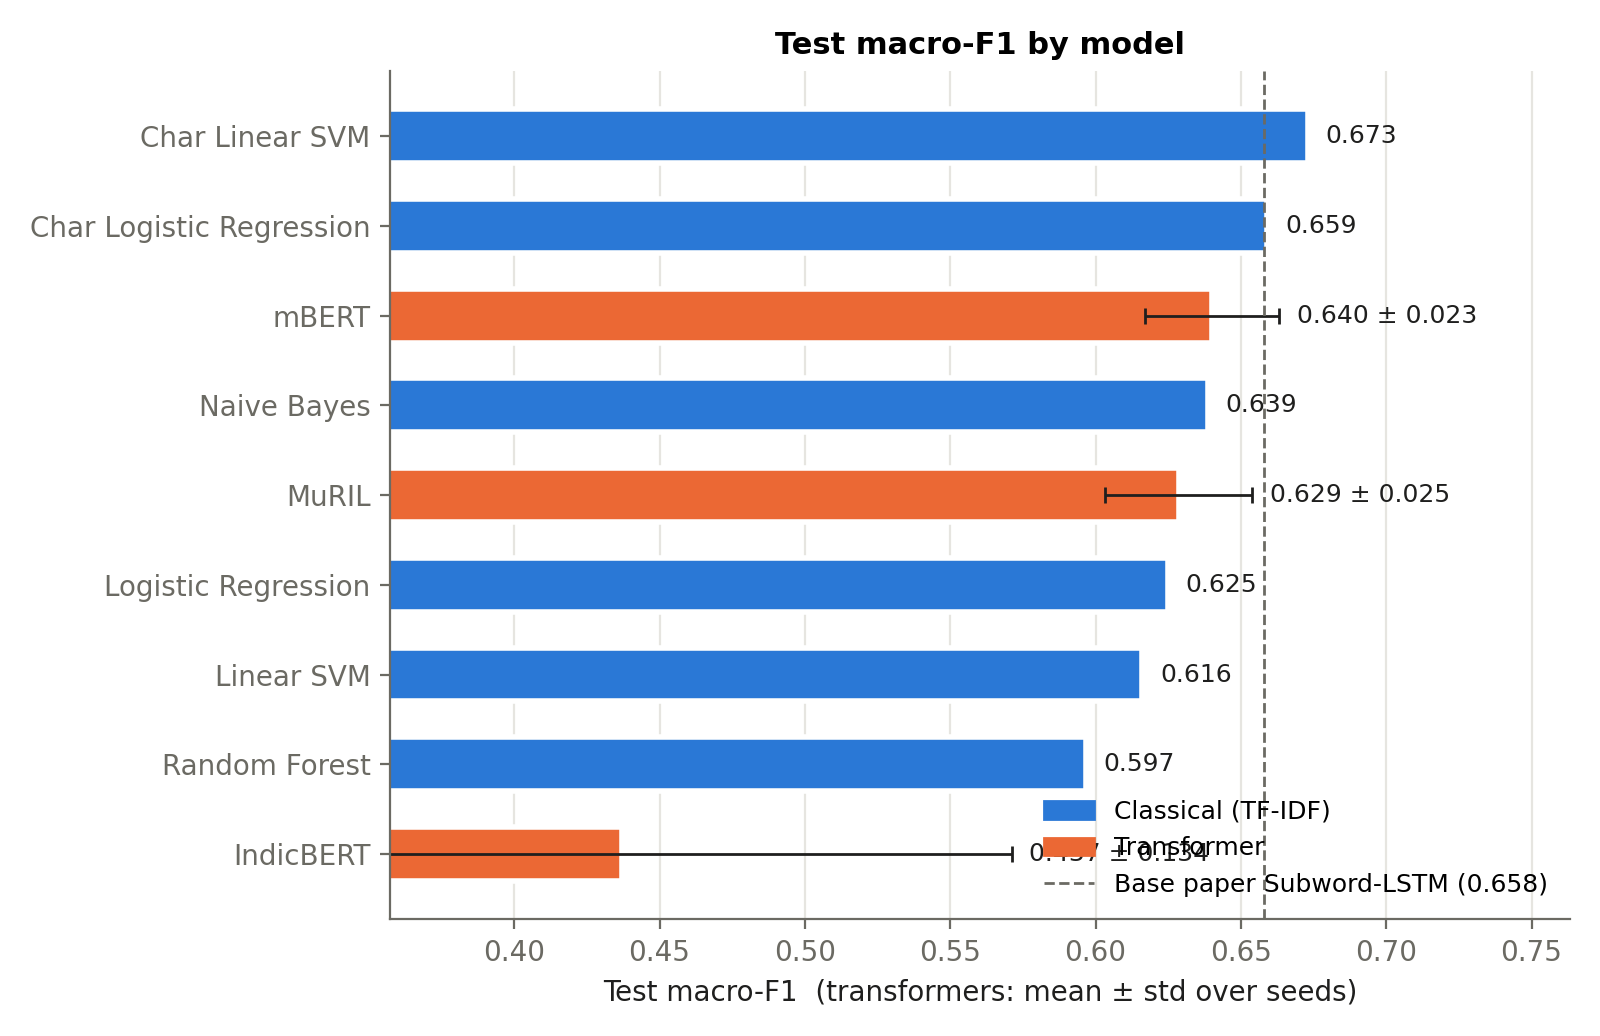

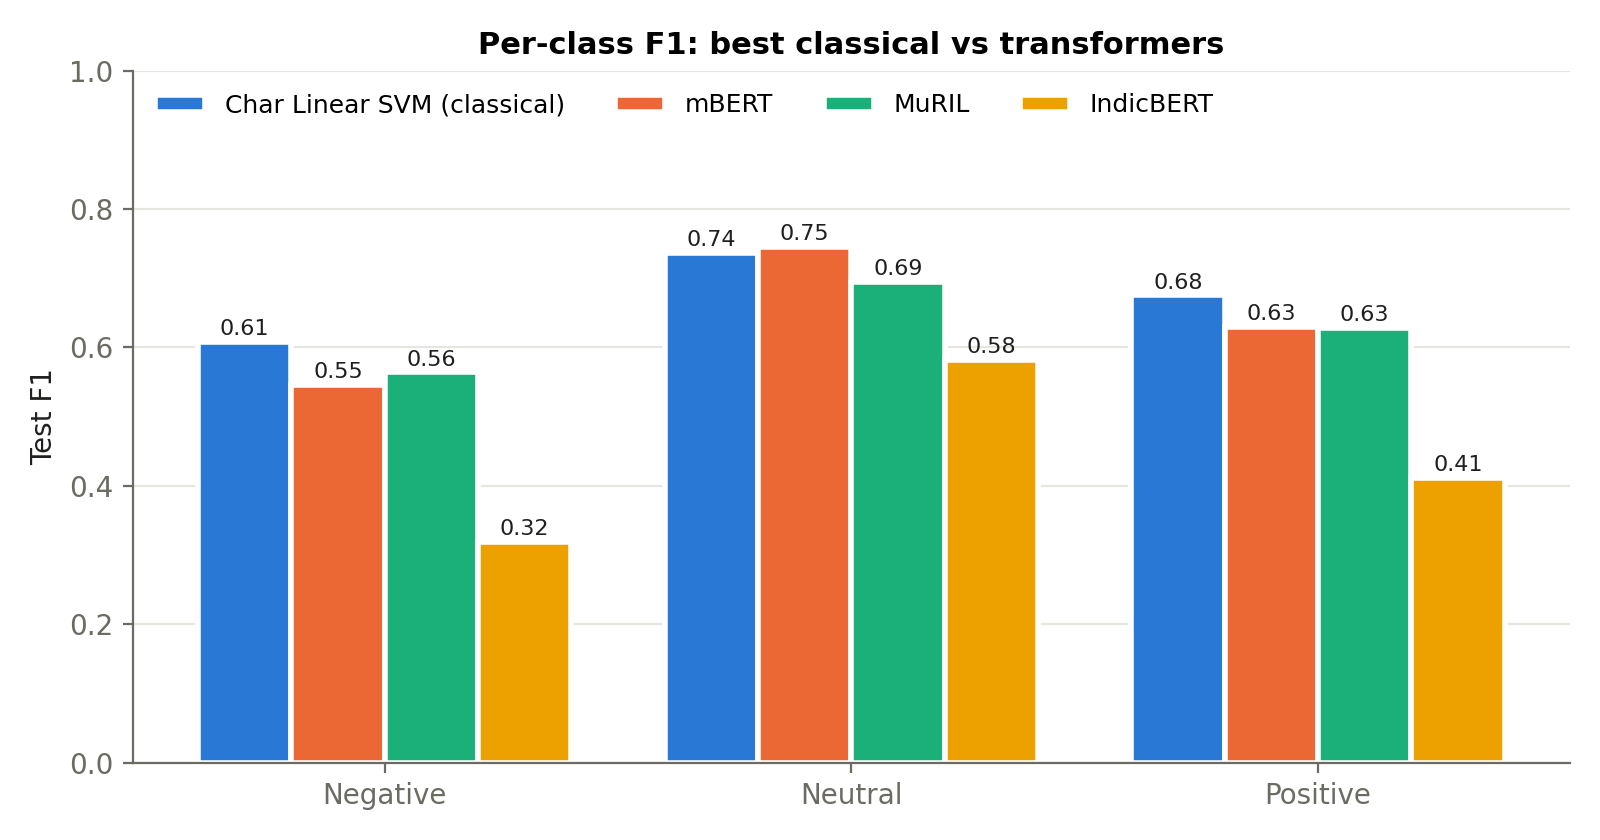

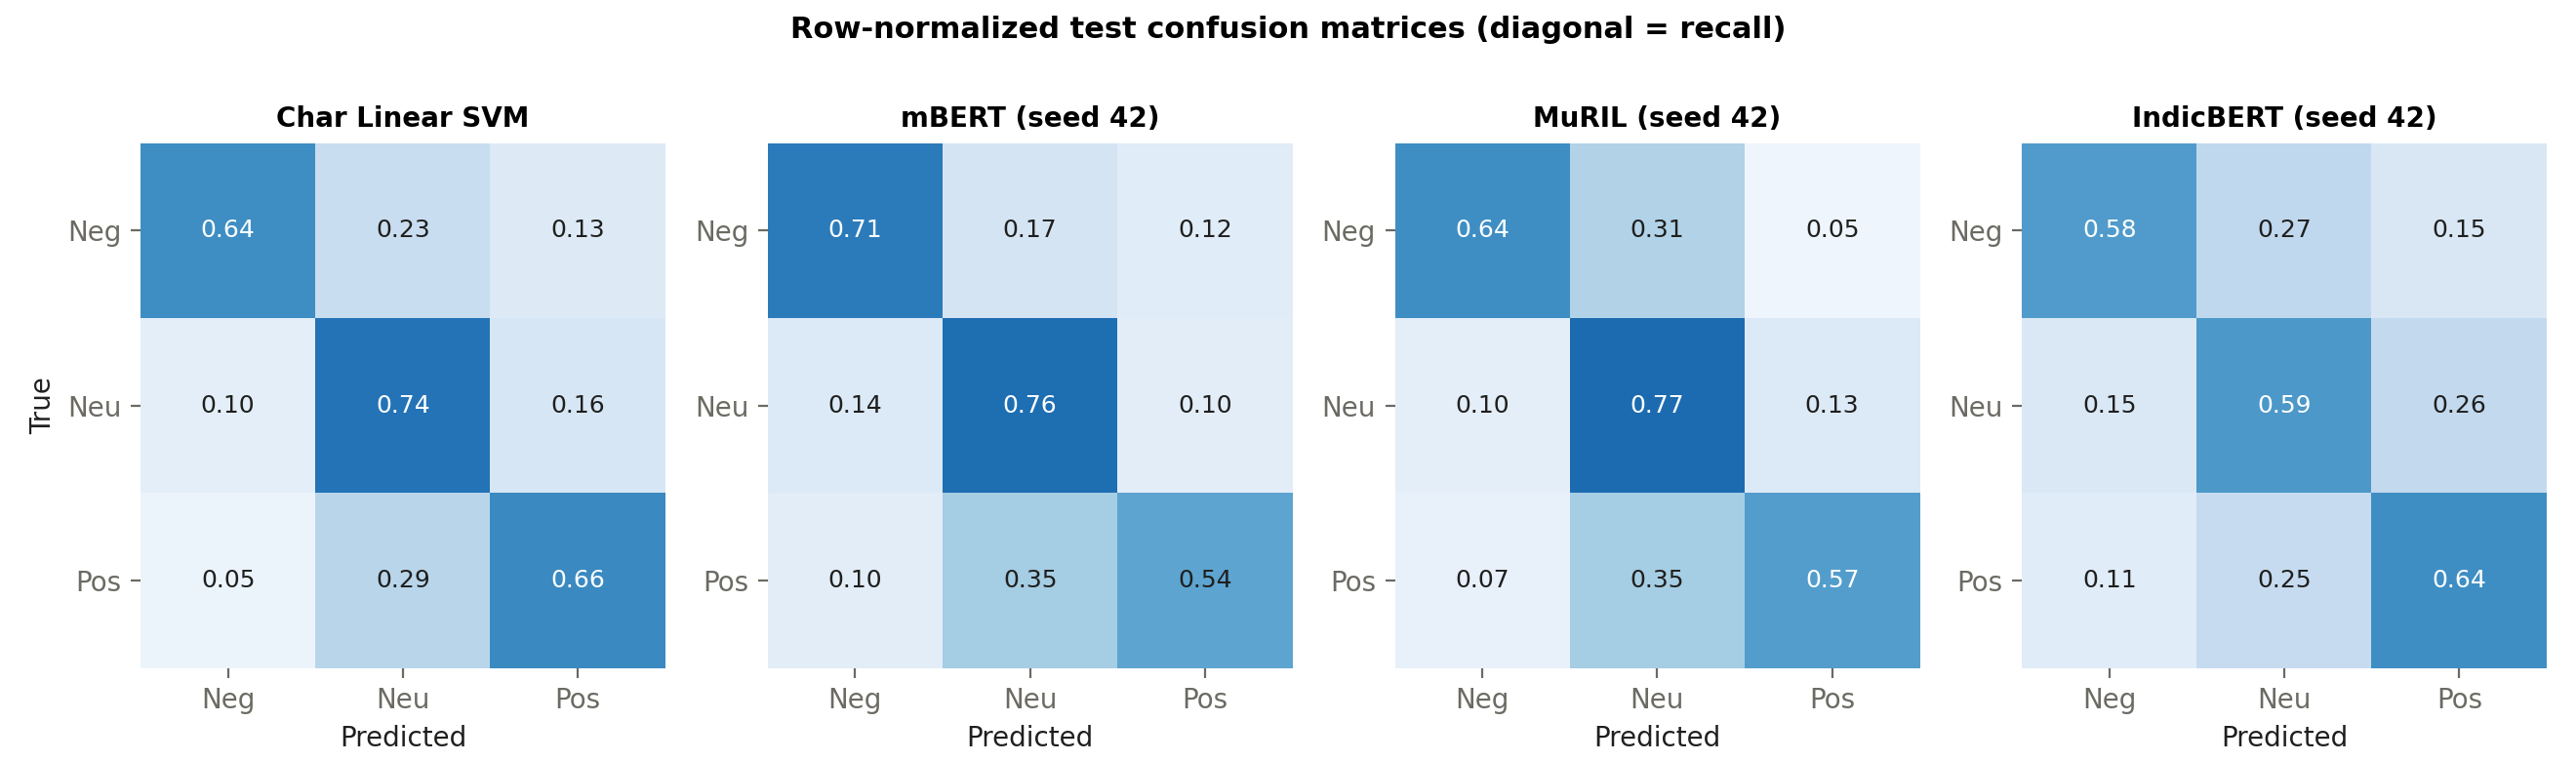

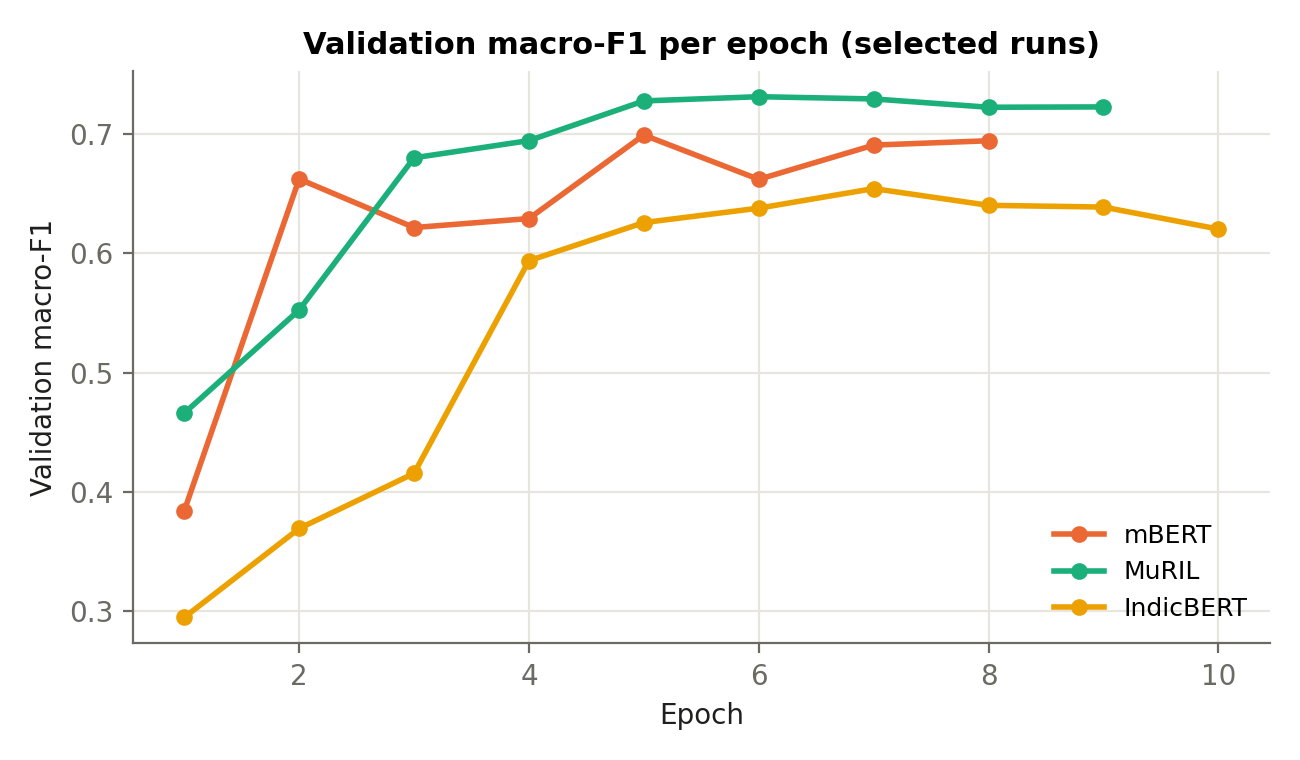

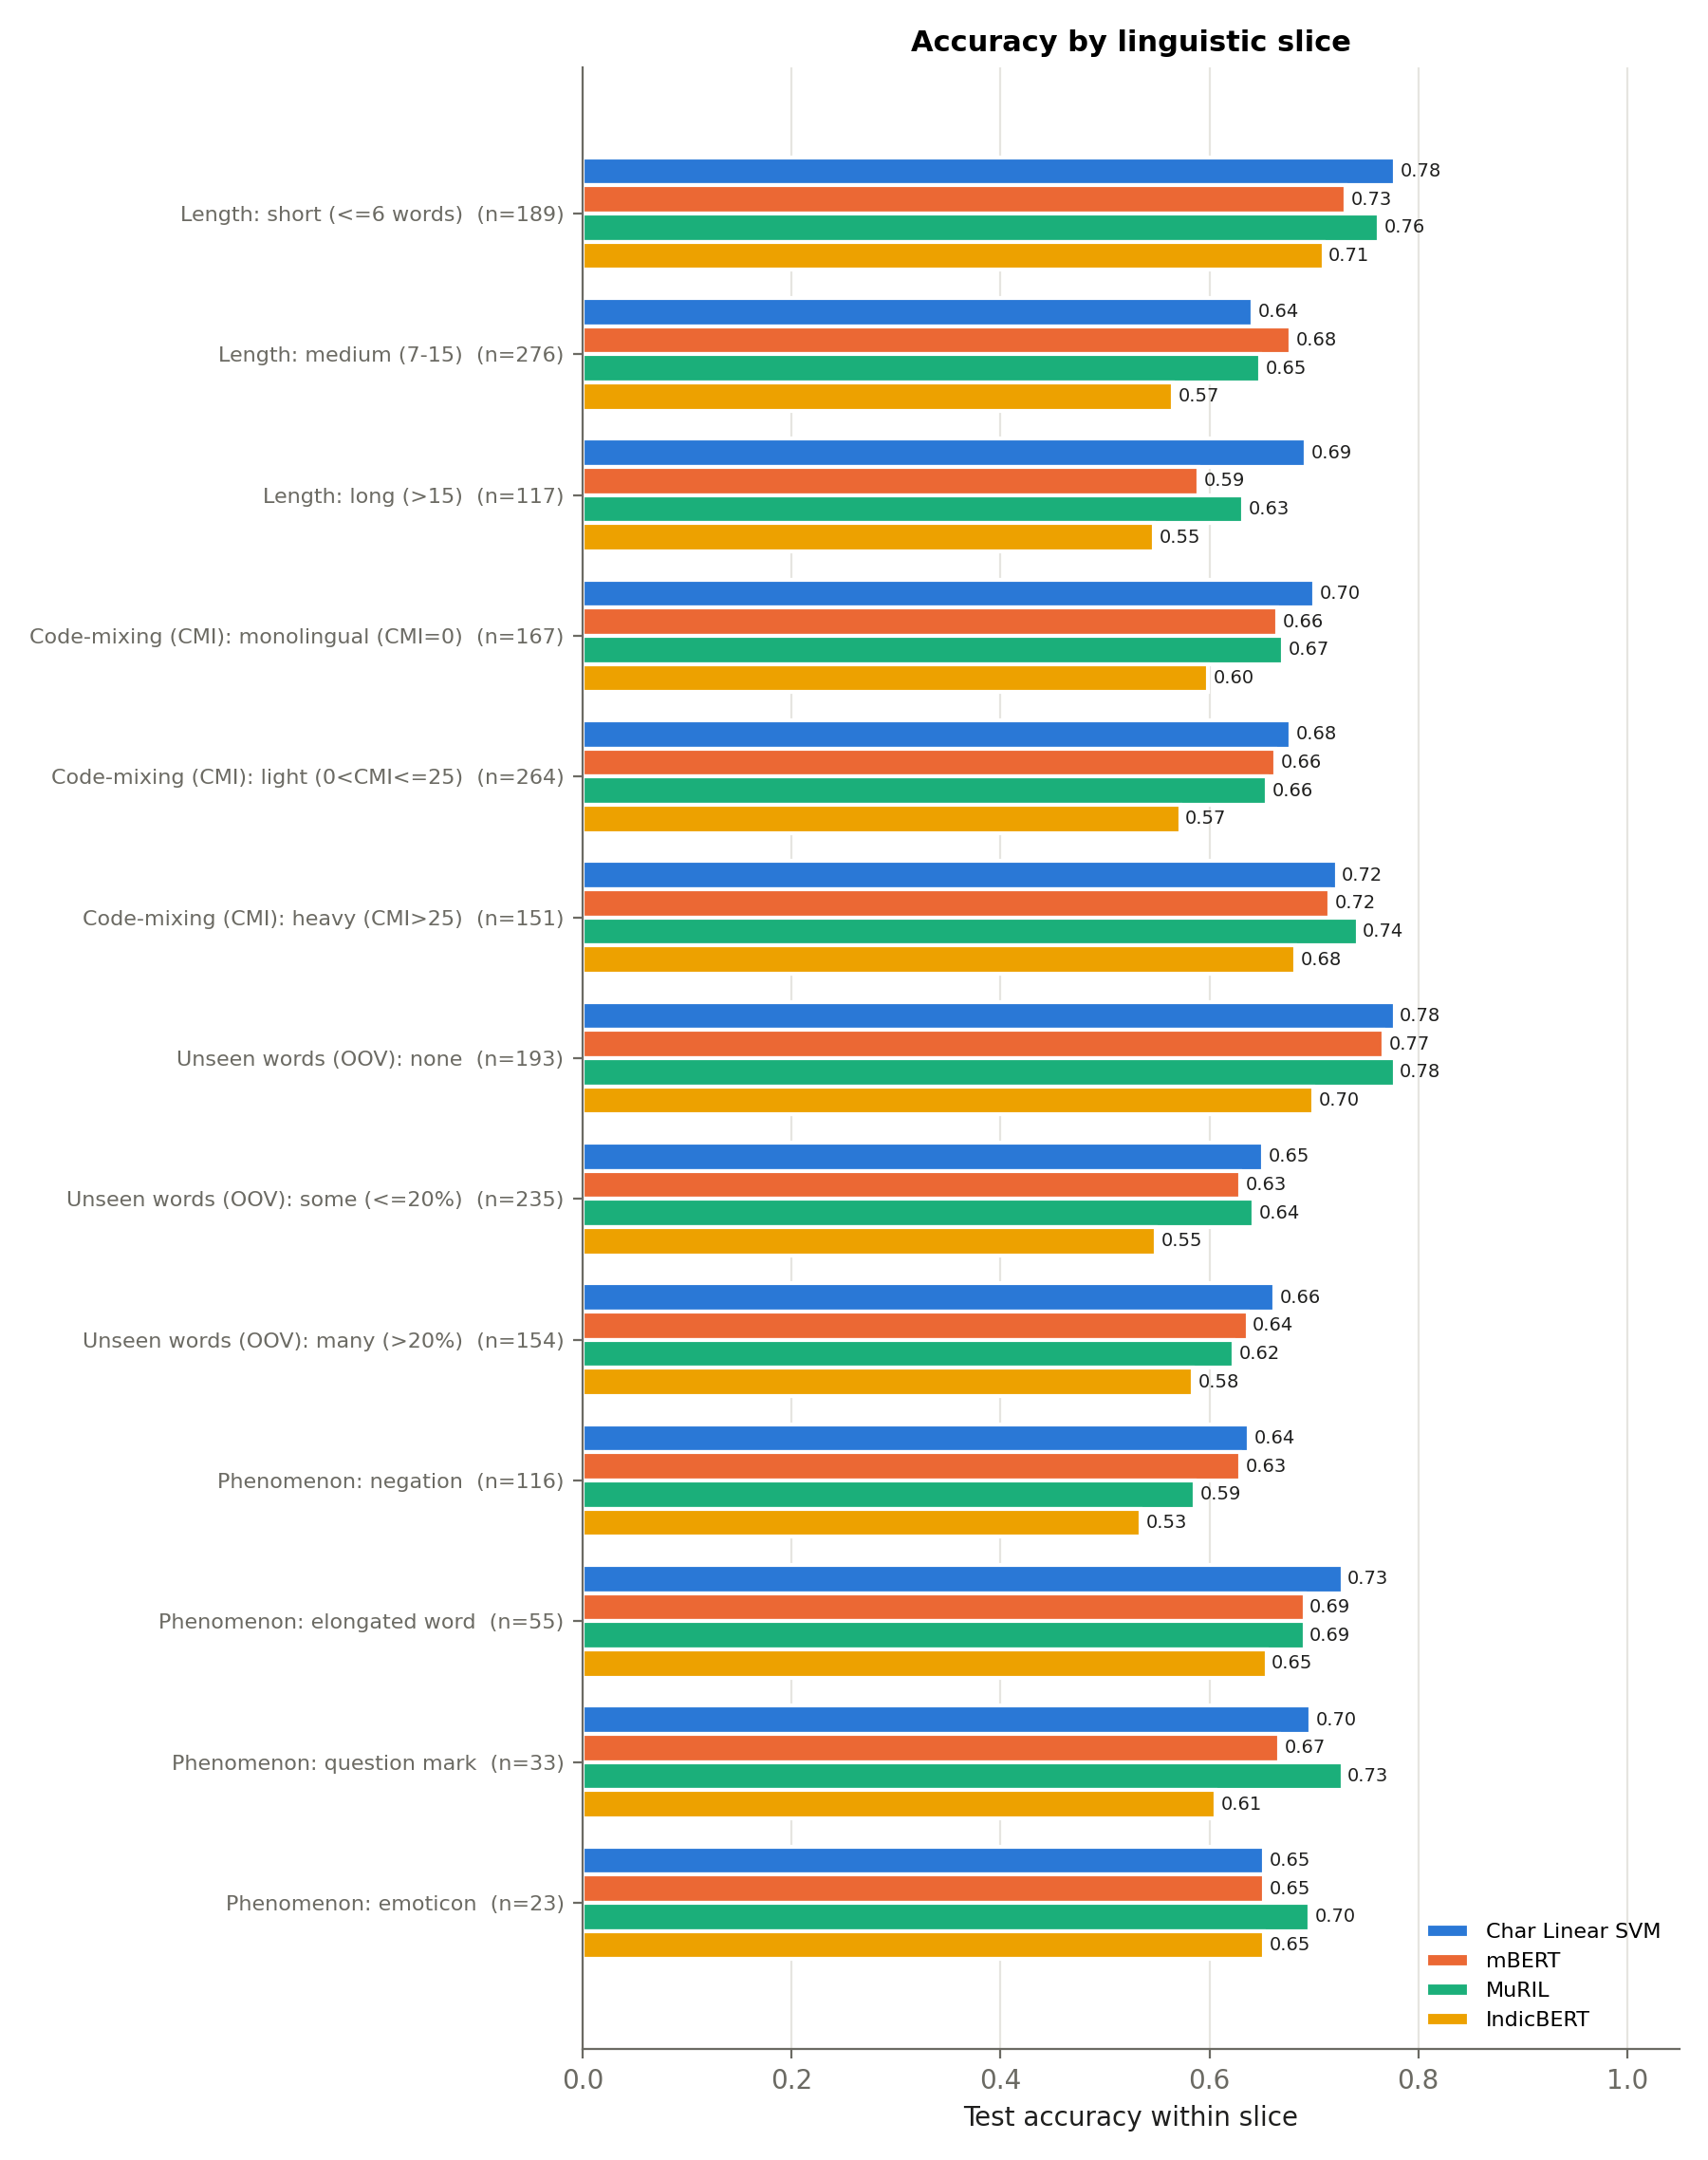

# Phase 7 — Error analysis

Best classical (by val): **Char Linear SVM**. Best transformer (by val): **MuRIL** (muril_lr3e-05_seed42_text_clean).

Language ID is an approximate frequency-dictionary heuristic (see script docstring).

## Code-mixing profile of the test set

- Mean CMI: 16.5; monolingual (CMI=0): 28.7%; heavy (CMI>25): 25.9%
- Mean share of English words per comment: 17.2%
- Comments with ≥1 word unseen in training: 66.8% (mean OOV rate 14.2%) — a proxy for spelling variation

## Accuracy by slice

| group | slice | n | Char Linear SVM acc | mBERT acc | MuRIL acc | IndicBERT acc |
|---|---|---|---|---|---|---|
| Length | short (<=6 words) | 189 | 0.778 | 0.730 | 0.762 | 0.709 |
| Length | medium (7-15) | 276 | 0.641 | 0.678 | 0.649 | 0.565 |
| Length | long (>15) | 117 | 0.692 | 0.590 | 0.632 | 0.547 |
| Code-mixing (CMI) | monolingual (CMI=0) | 167 | 0.701 | 0.665 | 0.671 | 0.599 |
| Code-mixing (CMI) | light (0<CMI<=25) | 264 | 0.678 | 0.663 | 0.655 | 0.572 |
| Code-mixing (CMI) | heavy (CMI>25) | 151 | 0.722 | 0.715 | 0.742 | 0.682 |
| Unseen words (OOV) | none | 193 | 0.777 | 0.767 | 0.777 | 0.699 |
| Unseen words (OOV) | some (<=20%) | 235 | 0.651 | 0.630 | 0.643 | 0.549 |
| Unseen words (OOV) | many (>20%) | 154 | 0.662 | 0.636 | 0.623 | 0.584 |
| Phenomenon | negation | 116 | 0.638 | 0.629 | 0.586 | 0.534 |
| Phenomenon | elongated word | 55 | 0.727 | 0.691 | 0.691 | 0.655 |
| Phenomenon | question mark | 33 | 0.697 | 0.667 | 0.727 | 0.606 |
| Phenomenon | emoticon | 23 | 0.652 | 0.652 | 0.696 | 0.652 |
| All | all test | 582 | 0.696 | 0.677 | 0.682 | 0.608 |

## Which classes get confused (count of test errors)

| Model | Neu↔Pos | Neg↔Neu | Neg↔Pos | Total errors |
|---|---|---|---|---|
| Char Linear SVM | 106 | 49 | 22 | 177 |
| mBERT | 102 | 55 | 31 | 188 |
| MuRIL | 111 | 55 | 19 | 185 |
| IndicBERT | 126 | 66 | 36 | 228 |

## Char Linear SVM vs MuRIL: who gets what right

| Outcome | n | % | mean OOV rate | mean CMI |
|---|---|---|---|---|
| both correct | 342 | 58.8% | 12.8% | 17.1 |
| only transformer correct | 55 | 9.5% | 14.9% | 18.2 |
| only classical correct | 63 | 10.8% | 15.0% | 16.1 |
| both wrong | 122 | 21.0% | 17.4% | 14.4 |

Examples (see `error_analysis/disagreements.csv` for all):

**only transformer correct:**
- "suna ha ap sub comments parhtay hain :* <3" — gold Neutral; classical Positive; transformer Neutral
- "Modije mera request hai ke ap apna whatsapp no de take mai live pic apko dekha saku" — gold Neutral; classical Positive; transformer Neutral
- "friends tum sab salman khan ku thaknah chati hu. ...???" — gold Neutral; classical Positive; transformer Neutral
- "Main ne tu kbi in romurs py yakeen kiya hi ni tha Bhai jaan" — gold Negative; classical Neutral; transformer Negative

**only classical correct:**
- "Aaaaaaa jaaaaaoooooo bhaiiiiiiiiiiiiiiiiiii knha busy hooooo ham wait kr rhe h" — gold Neutral; classical Neutral; transformer Positive
- "Javab nahi hai" — gold Neutral; classical Neutral; transformer Negative
- "nic song . bhi jan" — gold Positive; classical Positive; transformer Neutral
- "Advance mai eid mobarak bhai" — gold Neutral; classical Neutral; transformer Positive

**both wrong:**
- "Sala kutta kamena amara time west kara tia salman" — gold Positive; classical Negative; transformer Negative
- "Sllam bhai jaan EIDmubarakh." — gold Neutral; classical Positive; transformer Positive
- "ye tumse jalne walo k kaam h bhai" — gold Negative; classical Positive; transformer Neutral
- "jo jo gali diya hai sabko sunna hoga ab" — gold Negative; classical Neutral; transformer Neutral

## MuRIL: most confident errors (sarcasm / label-noise candidates)

- (0.93) "akele modi kya ker sakte hai.........akela aadmi pahad nhi khod sakta" — gold Neutral, predicted Negative
- (0.93) "paye kuppi puthe vichil" — gold Neutral, predicted Negative
- (0.93) "Koi bhi yeh chutiyo Salman Khan picture nahi dekhne musalmano be care ful picture ko flop karne ha" — gold Positive, predicted Negative
- (0.93) "abe salman khan yaha logo ko bewakuf bana raha he aur log ban b rahe he per me nahi banoonga samjha be bajrangi" — gold Neutral, predicted Negative
- (0.93) "Sb kh rhe h fake id fake id . Aap ko proove krna chahiye aap hi ho." — gold Positive, predicted Negative
- (0.93) "Jo salman se pyar karte h wo islaam se pyar nhi karte" — gold Positive, predicted Negative
- (0.93) "Sala kutta kamena amara time west kara tia salman" — gold Positive, predicted Negative
- (0.93) "Sallman ki photos uplod krke fb ko khrab mt kro" — gold Neutral, predicted Negative

## Manual annotation

`error_analysis/manual_annotation_sheet.csv` holds 100 sampled MuRIL errors. Suggested `category` values: sarcasm/irony, spelling-variant, negation, mixed/implicit sentiment, needs-context (named entity / event), label-noise, other.

## Tokenizer fertility (sub-word pieces per word, test set)

| Tokenizer | Words | Pieces/word | % split into ≥3 | % kept whole | % [UNK] |
|---|---|---|---|---|---|
| mBERT | hi (5202) | 1.80 | 12.8 | 37.1 | 0.00 |
| mBERT | en (1162) | 1.18 | 3.8 | 86.0 | 0.00 |
| mBERT | all (6364) | 1.69 | 11.1 | 46.0 | 0.00 |
| MuRIL | hi (5202) | 1.48 | 8.4 | 63.8 | 0.00 |
| MuRIL | en (1162) | 1.05 | 0.4 | 95.1 | 0.00 |
| MuRIL | all (6364) | 1.40 | 6.9 | 69.5 | 0.00 |
| IndicBERT | hi (5202) | 1.91 | 16.4 | 30.8 | 0.00 |
| IndicBERT | en (1162) | 1.15 | 0.7 | 85.9 | 0.00 |
| IndicBERT | all (6364) | 1.77 | 13.5 | 40.9 | 0.00 |


In [ ]:
!python src/evaluate.py
!python src/error_analysis.py --fertility > /dev/null
sync()
from IPython.display import Markdown, Image, display
display(Markdown(open('outputs/results/phase6_summary.md').read()))
for f in ['macro_f1_comparison', 'per_class_f1', 'confusion_matrices_grid', 'training_curves', 'error_slices']:
    display(Image(f'outputs/figures/{f}.png', width=750))
display(Markdown(open('outputs/results/phase7_summary.md').read()))

In [ ]:
!zip -qr /content/phase5_outputs_run2.zip outputs -x 'outputs/models/*'
!cp /content/phase5_outputs_run2.zip "$DRIVE_OUT/"
from google.colab import files
files.download('/content/phase5_outputs_run2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>